In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/adilashrafi/bank-marketing-classification-task/bank_data.csv


In [2]:
import os 
import pandas as pd
import numpy as np

data_path="/kaggle/input/datasets/adilashrafi/bank-marketing-classification-task"

print(os.listdir(data_path))

['bank_data.csv']


In [3]:
file_path=data_path+"/bank_data.csv"

df=pd.read_csv(file_path,sep=",")
print("Shape:", df.shape)
print(df.head())
df.info()

Shape: (4521, 18)
   Unnamed: 0  age          job  marital  education default  balance housing  \
0           0   30   unemployed  married    primary      no     1787      no   
1           1   33     services  married  secondary      no     4789     yes   
2           2   35   management   single   tertiary      no     1350     yes   
3           3   30   management  married   tertiary      no     1476     yes   
4           4   59  blue-collar  married  secondary      no        0     yes   

  loan   contact  day month  duration  campaign  pdays  previous poutcome   y  
0   no  cellular   19   oct        79         1     -1         0  unknown  no  
1  yes  cellular   11   may       220         1    339         4  failure  no  
2   no  cellular   16   apr       185         1    330         1  failure  no  
3  yes   unknown    3   jun       199         4     -1         0  unknown  no  
4   no   unknown    5   may       226         1     -1         0  unknown  no  
<class 'pandas.core.f

In [4]:
print(df.columns.tolist())

['Unnamed: 0', 'age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [5]:
df=df.drop(columns=["Unnamed: 0"])

In [6]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True)*100)

print(df.isnull().sum())
print(df.dtypes)

y
no     4000
yes     521
Name: count, dtype: int64
y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object


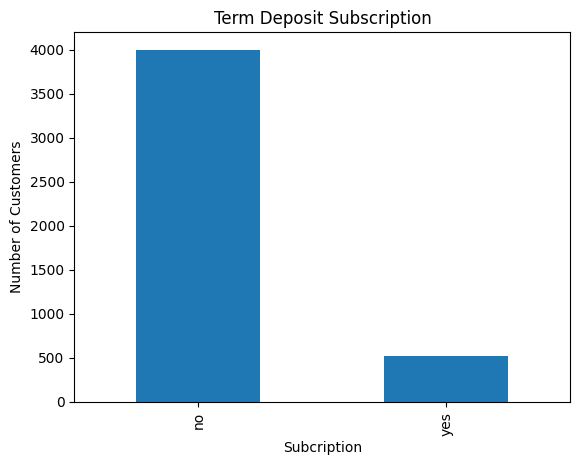

In [7]:
import matplotlib.pyplot as plt

df["y"].value_counts().plot(kind="bar")
plt.title("Term Deposit Subscription")
plt.xlabel("Subcription")
plt.ylabel("Number of Customers")
plt.show()

In [8]:
X=df.drop("y",axis=1)
y=df["y"].map({"no": 0,"yes":1})

print("Features:", X.shape)
print("Target:", y.shape)

Features: (4521, 16)
Target: (4521,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(3616, 16) (905, 16)
y
0    0.884679
1    0.115321
Name: proportion, dtype: float64
y
0    0.885083
1    0.114917
Name: proportion, dtype: float64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features=X.select_dtypes(include=["int64","float64"]).columns
categorical_features=X.select_dtypes(include=["object","category"]).columns

numeric_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor=ColumnTransformer([
    ("num",numeric_pipeline,numeric_features),
    ("cat",categorical_pipeline, categorical_features)
])

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

dummy=DummyClassifier(strategy="most_frequent")
dummy.fit(X_train,y_train)

dummy_predictions=dummy.predict(X_test)

print("Dummy Accuracy:", accuracy_score(y_test, dummy_predictions))

Dummy Accuracy: 0.8850828729281768


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
roc_auc_score,
average_precision_score
)

models={
    "Logistic Regression":LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Decision Tree":DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest":RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results=[]

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

comparison_models={
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest":RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

scoring = {
    "precision":"precision",
    "recall":"recall",
    "f1":"f1",
    "roc_auc":"roc_auc",
    "pr_auc":"average_precision"
}


cv_results = []

for name, classifier in comparison_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
from IPython.display import display
display(
    cv_results_df.sort_values(
        "PR-AUC", ascending=False
    )
)


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.392304,0.767384,0.518739,0.893886,0.529160
2,Random Forest,0.549801,0.398279,0.459320,0.892181,0.519954
1,Decision Tree,0.316488,0.674125,0.429801,0.737894,0.367415


In [14]:
X_fit, X_val, y_fit, y_val=train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [15]:
from sklearn.model_selection import GridSearchCV

tuning_pipeline=Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

param_grid={
    "model__C":[0.01,0.1,1,10,100]
}

grid_search=GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="average_precision",
    n_jobs=-1
)

grid_search.fit(X_fit,y_fit)

print("Best parameters:", grid_search.best_params_)
print("Best CV PR-AUC:", grid_search.best_score_)

Best parameters: {'model__C': 1}
Best CV PR-AUC: 0.5112495629767426


In [16]:
best_model = grid_search.best_estimator_

In [17]:
from sklearn.metrics import precision_score, recall_score, f1_score

val_probabilities=best_model.predict_proba(X_val)[:,1]

threshold_results=[]

for threshold in np.arange(0.10,0.61,0.01):
    val_predictions=(val_probabilities>=threshold).astype(int)
    threshold_results.append({
        "Threshold":threshold,
        "Precision":precision_score(
            y_val,val_predictions,zero_division=0
        ),
        "Recall":recall_score(
            y_val,val_predictions,zero_division=0
        ),
        "F1":f1_score(
            y_val,val_predictions,zero_division=0
        )
    })

threshold_df=pd.DataFrame(threshold_results)
best_threshold=threshold_df.loc[threshold_df["F1"].idxmax(), "Threshold"]

from IPython.display import display
print("Selected threshold:", best_threshold)
display(threshold_df.sort_values("F1",ascending=False).head(10))

Selected threshold: 0.4999999999999998


,Threshold,Precision,Recall,F1
40,0.50,0.408284,0.831325,0.547619
50,0.60,0.435714,0.734940,0.547085
39,0.49,0.403509,0.831325,0.543307
49,0.59,0.426573,0.734940,0.539823
41,0.51,0.403614,0.807229,0.538153
38,0.48,0.391061,0.843373,0.534351
37,0.47,0.385870,0.855422,0.531835
42,0.52,0.401235,0.783133,0.530612
48,0.58,0.414966,0.734940,0.530435
44,0.54,0.406452,0.759036,0.529412


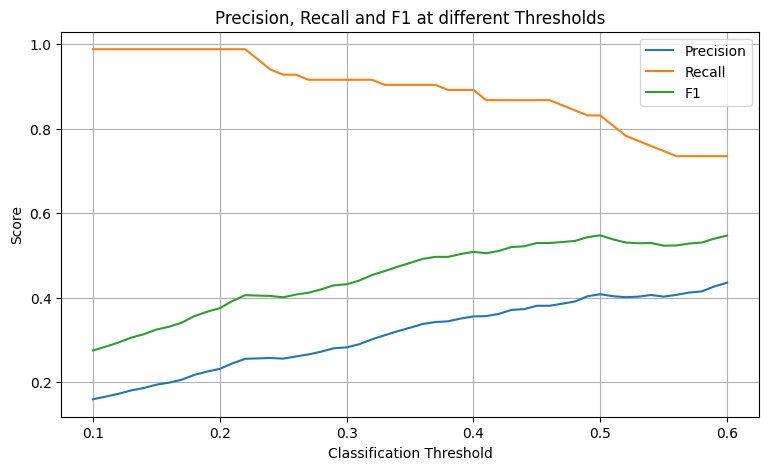

In [18]:
plt.figure(figsize=(9,5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1'],
    label='F1'
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 at different Thresholds")
plt.legend()
plt.grid()
plt.show()

In [19]:
final_model=grid_search.best_estimator_
final_model.fit(X_train,y_train)
test_probabilities=final_model.predict_proba(X_test)[:,1]
test_predictions=(
    test_probabilities>=best_threshold
).astype(int)

In [20]:
from sklearn.metrics import classification_report

print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions))
print("Recall:", recall_score(y_test, test_predictions))
print("F1:", f1_score(y_test, test_predictions))
print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))
print("PR-AUC:", average_precision_score(y_test, test_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

Accuracy: 0.8232044198895028
Precision: 0.37155963302752293
Recall: 0.7788461538461539
F1: 0.5031055900621118
ROC-AUC: 0.8908095649668683
PR-AUC: 0.4558693169540234

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.83      0.89       801
           1       0.37      0.78      0.50       104

    accuracy                           0.82       905
   macro avg       0.67      0.80      0.70       905
weighted avg       0.90      0.82      0.85       905



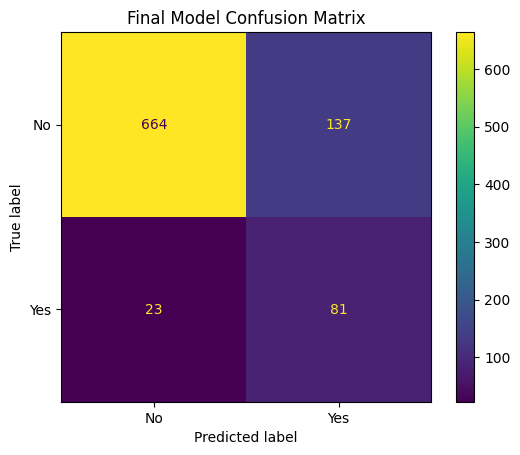

[[664 137]
 [ 23  81]]


In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm=confusion_matrix(y_test,test_predictions)

display=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No","Yes"]
)

display.plot()
plt.title("Final Model Confusion Matrix")
plt.show()

print(cm)

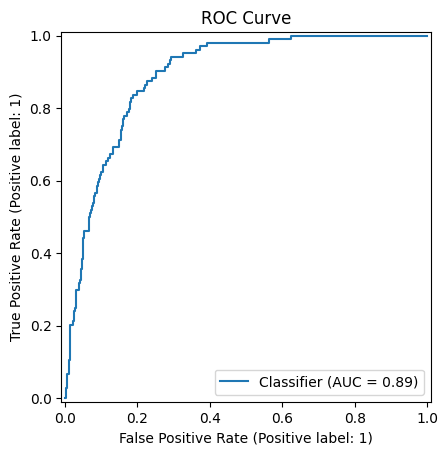

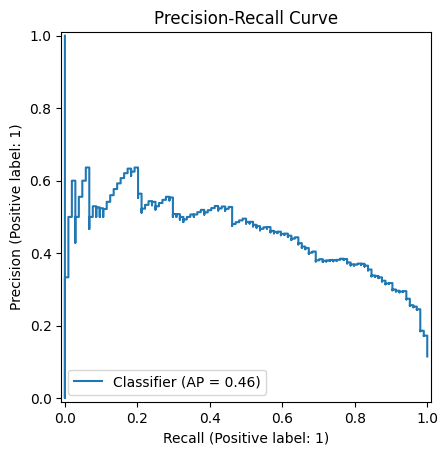

In [22]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("ROC Curve")
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("Precision-Recall Curve")
plt.show()

In [23]:
feature_names = (
    final_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    final_model
    .named_steps["model"]
    .coef_[0]
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

from IPython.display import display as show_table

top_features = (
    feature_importance
    .sort_values("Absolute_Coefficient", ascending=False)
    .head(15)
)

show_table(top_features)

,Feature,Coefficient,Absolute_Coefficient
45,cat__month_oct,1.804370,1.804370
49,cat__poutcome_success,1.675186,1.675186
42,cat__month_mar,1.640650,1.640650
3,num__duration,1.529267,1.529267
39,cat__month_jan,-1.337988,1.337988
50,cat__poutcome_unknown,-1.013068,1.013068
43,cat__month_may,-0.891270,0.891270
40,cat__month_jul,-0.806400,0.806400
44,cat__month_nov,-0.799598,0.799598
34,cat__contact_unknown,-0.787590,0.787590


In [24]:
import joblib

joblib.dump(
    {
        "model": final_model,
        "threshold": best_threshold
    },
    "bank_marketing_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [25]:
saved_artifact = joblib.load("bank_marketing_model.pkl")

loaded_model = saved_artifact["model"]
loaded_threshold = saved_artifact["threshold"]

probabilities = loaded_model.predict_proba(X_test.head(5))[:, 1]

new_predictions = (
    probabilities >= loaded_threshold
).astype(int)

print(new_predictions)

[1 0 0 0 0]
